In [ ]:
# 1. Import Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
from google.colab import files

uploaded = files.upload()

In [ ]:
# 2. Load Datasets
train = pd.read_csv("train.csv")
features = pd.read_csv("features.csv")
stores = pd.read_csv("stores.csv")

In [ ]:
print("Train dataset:")
print(train.head())

print("\nFeatures dataset:")
print(features.head())

print("\nStores dataset:")
print(stores.head())

Train dataset:
   Store  Dept        Date  Weekly_Sales  IsHoliday
0      1     1  2010-02-05      24924.50      False
1      1     1  2010-02-12      46039.49       True
2      1     1  2010-02-19      41595.55      False
3      1     1  2010-02-26      19403.54      False
4      1     1  2010-03-05      21827.90      False

Features dataset:
   Store        Date  Temperature  Fuel_Price  MarkDown1  MarkDown2  \
0      1  2010-02-05        42.31       2.572        NaN        NaN   
1      1  2010-02-12        38.51       2.548        NaN        NaN   
2      1  2010-02-19        39.93       2.514        NaN        NaN   
3      1  2010-02-26        46.63       2.561        NaN        NaN   
4      1  2010-03-05        46.50       2.625        NaN        NaN   

   MarkDown3  MarkDown4  MarkDown5         CPI  Unemployment  IsHoliday  
0        NaN        NaN        NaN  211.096358         8.106      False  
1        NaN        NaN        NaN  211.242170         8.106       True  
2    

In [ ]:
print("Train shape:", train.shape)
print("Features shape:", features.shape)
print("Stores shape:", stores.shape)

Train shape: (421570, 5)
Features shape: (8190, 12)
Stores shape: (45, 3)


In [ ]:
print("Train columns:")
print(train.columns.tolist())

print("\nFeatures columns:")
print(features.columns.tolist())

print("\nStores columns:")
print(stores.columns.tolist())

Train columns:
['Store', 'Dept', 'Date', 'Weekly_Sales', 'IsHoliday']

Features columns:
['Store', 'Date', 'Temperature', 'Fuel_Price', 'MarkDown1', 'MarkDown2', 'MarkDown3', 'MarkDown4', 'MarkDown5', 'CPI', 'Unemployment', 'IsHoliday']

Stores columns:
['Store', 'Type', 'Size']


In [ ]:
print("Missing values in train:")
print(train.isnull().sum())

print("\nMissing values in features:")
print(features.isnull().sum())

print("\nMissing values in stores:")
print(stores.isnull().sum())

Missing values in train:
Store           0
Dept            0
Date            0
Weekly_Sales    0
IsHoliday       0
dtype: int64

Missing values in features:
Store              0
Date               0
Temperature        0
Fuel_Price         0
MarkDown1       4158
MarkDown2       5269
MarkDown3       4577
MarkDown4       4726
MarkDown5       4140
CPI              585
Unemployment     585
IsHoliday          0
dtype: int64

Missing values in stores:
Store    0
Type     0
Size     0
dtype: int64


In [ ]:
train.describe()

,Store,Dept,Weekly_Sales
count,421570.000000,421570.000000,421570.000000
mean,22.200546,44.260317,15981.258123
std,12.785297,30.492054,22711.183519
min,1.000000,1.000000,-4988.940000
25%,11.000000,18.000000,2079.650000
50%,22.000000,37.000000,7612.030000
75%,33.000000,74.000000,20205.852500
max,45.000000,99.000000,693099.360000


In [ ]:
## Selecting Store 1 & Department 1
train['Date'] = pd.to_datetime(train['Date'])

print("Start date:", train['Date'].min())
print("End date:", train['Date'].max())

Start date: 2010-02-05 00:00:00
End date: 2012-10-26 00:00:00


In [ ]:
store_1 = train[train['Store'] == 1]

print("Number of records:", len(store_1))
print(store_1.head())

Number of records: 10244
   Store  Dept       Date  Weekly_Sales  IsHoliday
0      1     1 2010-02-05      24924.50      False
1      1     1 2010-02-12      46039.49       True
2      1     1 2010-02-19      41595.55      False
3      1     1 2010-02-26      19403.54      False
4      1     1 2010-03-05      21827.90      False


In [ ]:

store_dept = train[
    (train['Store'] == 1) &
    (train['Dept'] == 1)
].copy()

print("Number of records:", len(store_dept))
print(store_dept.head())

Number of records: 143
   Store  Dept       Date  Weekly_Sales  IsHoliday
0      1     1 2010-02-05      24924.50      False
1      1     1 2010-02-12      46039.49       True
2      1     1 2010-02-19      41595.55      False
3      1     1 2010-02-26      19403.54      False
4      1     1 2010-03-05      21827.90      False


In [ ]:
store_dept = store_dept.sort_values('Date').reset_index(drop=True)

store_dept.head()

,Store,Dept,Date,Weekly_Sales,IsHoliday
0,1,1,2010-02-05,24924.50,False
1,1,1,2010-02-12,46039.49,True
2,1,1,2010-02-19,41595.55,False
3,1,1,2010-02-26,19403.54,False
4,1,1,2010-03-05,21827.90,False


In [ ]:
# Data Validation
date_diff = store_dept['Date'].diff().dropna()

print(date_diff.value_counts())

Date
7 days    142
Name: count, dtype: int64


In [ ]:
print("Duplicate dates:", store_dept['Date'].duplicated().sum())

Duplicate dates: 0


In [ ]:
# 5. Exploratory Data Analysis (EDA)
print("Average weekly sales:", store_dept['Weekly_Sales'].mean())
print("Minimum weekly sales:", store_dept['Weekly_Sales'].min())
print("Maximum weekly sales:", store_dept['Weekly_Sales'].max())

Average weekly sales: 22513.322937062938
Minimum weekly sales: 14537.37
Maximum weekly sales: 57592.12


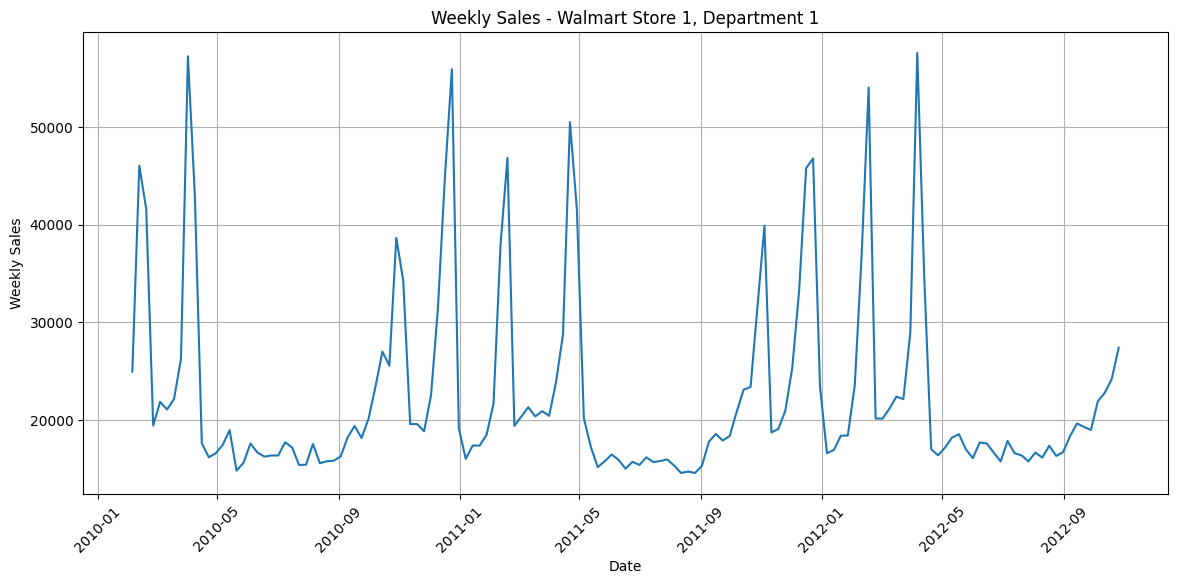

In [ ]:
plt.figure(figsize=(14, 6))

plt.plot(
    store_dept['Date'],
    store_dept['Weekly_Sales']
)

plt.title('Weekly Sales - Walmart Store 1, Department 1')
plt.xlabel('Date')
plt.ylabel('Weekly Sales')
plt.xticks(rotation=45)
plt.grid(True)

plt.show()

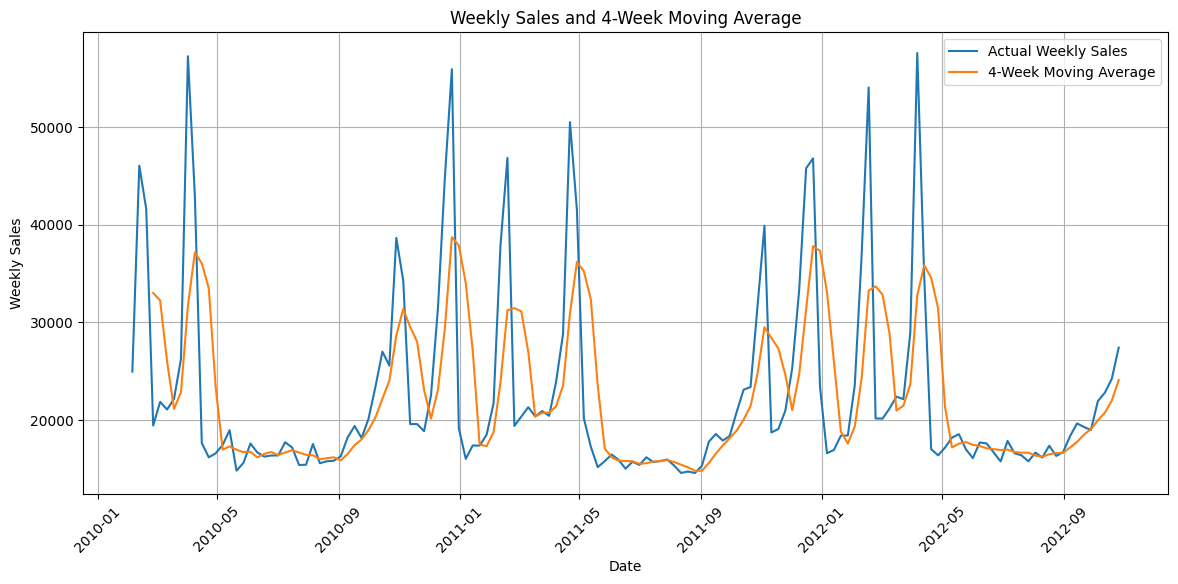

In [ ]:
store_dept['Rolling_4_Week'] = (
    store_dept['Weekly_Sales']
    .rolling(window=4)
    .mean()
)

plt.figure(figsize=(14, 6))

plt.plot(
    store_dept['Date'],
    store_dept['Weekly_Sales'],
    label='Actual Weekly Sales'
)

plt.plot(
    store_dept['Date'],
    store_dept['Rolling_4_Week'],
    label='4-Week Moving Average'
)

plt.title('Weekly Sales and 4-Week Moving Average')
plt.xlabel('Date')
plt.ylabel('Weekly Sales')
plt.xticks(rotation=45)
plt.legend()
plt.grid(True)

plt.show()

In [ ]:
print(store_dept['IsHoliday'].value_counts())

IsHoliday
False    133
True      10
Name: count, dtype: int64


In [ ]:
holiday_sales = store_dept.groupby('IsHoliday')['Weekly_Sales'].mean()

print(holiday_sales)

IsHoliday
False    22270.821353
True     25738.594000
Name: Weekly_Sales, dtype: float64


In [ ]:
top_sales = store_dept.nlargest(10, 'Weekly_Sales')[
    ['Date', 'Weekly_Sales', 'IsHoliday']
]

print(top_sales)

          Date  Weekly_Sales  IsHoliday
113 2012-04-06      57592.12      False
8   2010-04-02      57258.43      False
46  2010-12-24      55931.23      False
106 2012-02-17      54060.10      False
63  2011-04-22      50510.31      False
54  2011-02-18      46845.87      False
98  2011-12-23      46788.75      False
1   2010-02-12      46039.49       True
97  2011-12-16      45773.03      False
45  2010-12-17      44912.86      False


In [ ]:
store_dept['Week_of_Year'] = store_dept['Date'].dt.isocalendar().week.astype(int)

store_dept[['Date', 'Weekly_Sales', 'Week_of_Year']].head(10)

,Date,Weekly_Sales,Week_of_Year
0,2010-02-05,24924.50,5
1,2010-02-12,46039.49,6
2,2010-02-19,41595.55,7
3,2010-02-26,19403.54,8
4,2010-03-05,21827.90,9
5,2010-03-12,21043.39,10
6,2010-03-19,22136.64,11
7,2010-03-26,26229.21,12
8,2010-04-02,57258.43,13
9,2010-04-09,42960.91,14


In [ ]:
seasonality = (
    store_dept
    .groupby('Week_of_Year')['Weekly_Sales']
    .mean()
)

print(seasonality)

Week_of_Year
1     16275.965000
2     17127.050000
3     17853.285000
4     18419.670000
5     23366.916667
6     40305.050000
7     47500.506667
8     19630.530000
9     20756.180000
10    21154.620000
11    21612.583333
12    23072.670000
13    35536.460000
14    41475.606667
15    27014.513333
16    27877.283333
17    24805.033333
18    18233.190000
19    18108.696667
20    16142.536667
21    16095.193333
22    16685.910000
23    16729.046667
24    16251.060000
25    16214.980000
26    15806.486667
27    17220.333333
28    16457.290000
29    15825.036667
30    15678.470000
31    16477.423333
32    15398.703333
33    15920.023333
34    15539.213333
35    16066.430000
36    18087.930000
37    19168.643333
38    18411.106667
39    19126.560000
40    22030.026667
41    24273.300000
42    24360.036667
43    32537.213333
44    37062.470000
45    19119.465000
46    19301.750000
47    19865.770000
48    23905.525000
49    32401.785000
50    45342.945000
51    51359.990000
52    21237.730000

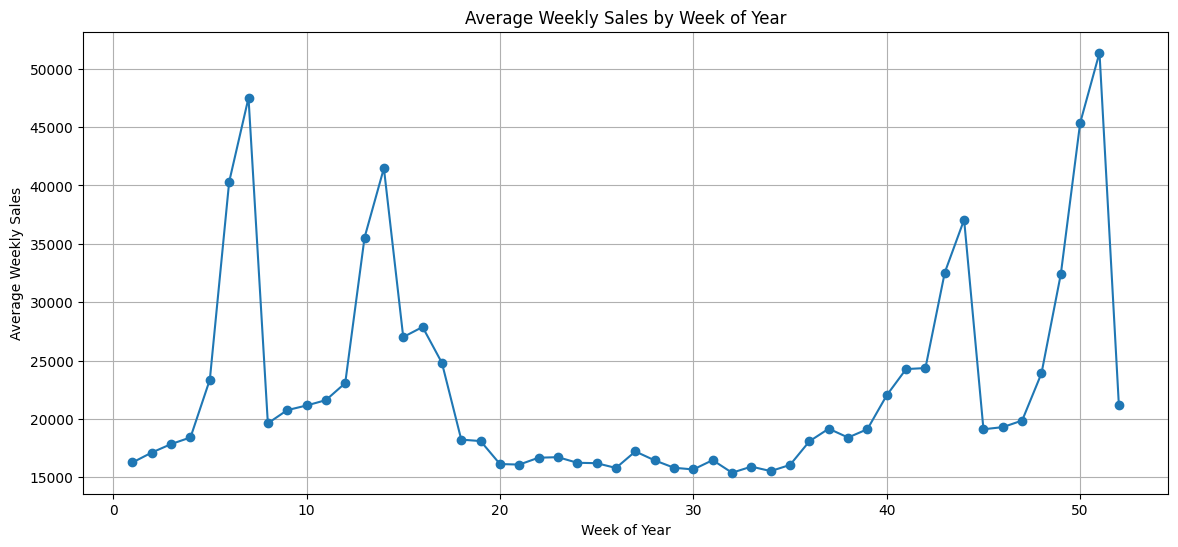

In [ ]:
plt.figure(figsize=(14, 6))

plt.plot(
    seasonality.index,
    seasonality.values,
    marker='o'
)

plt.title('Average Weekly Sales by Week of Year')
plt.xlabel('Week of Year')
plt.ylabel('Average Weekly Sales')
plt.grid(True)

plt.show()

In [ ]:
top_seasonal_weeks = (
    seasonality
    .sort_values(ascending=False)
    .head(10)
)

print(top_seasonal_weeks)

Week_of_Year
51    51359.990000
7     47500.506667
50    45342.945000
14    41475.606667
6     40305.050000
44    37062.470000
13    35536.460000
43    32537.213333
49    32401.785000
16    27877.283333
Name: Weekly_Sales, dtype: float64


In [ ]:
low_seasonal_weeks = (
    seasonality
    .sort_values()
    .head(10)
)

print(low_seasonal_weeks)

Week_of_Year
32    15398.703333
34    15539.213333
30    15678.470000
26    15806.486667
29    15825.036667
33    15920.023333
35    16066.430000
21    16095.193333
20    16142.536667
25    16214.980000
Name: Weekly_Sales, dtype: float64


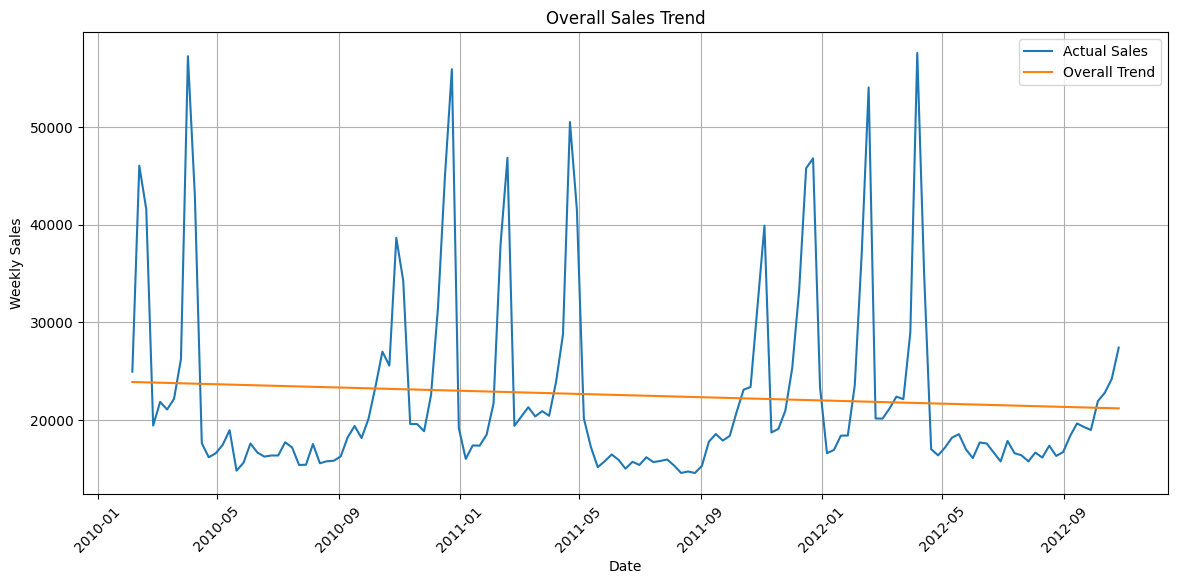

In [ ]:
x = np.arange(len(store_dept))

y = store_dept['Weekly_Sales'].values

trend_model = np.polyfit(x, y, 1)

trend_line = np.polyval(trend_model, x)

plt.figure(figsize=(14, 6))

plt.plot(
    store_dept['Date'],
    y,
    label='Actual Sales'
)

plt.plot(
    store_dept['Date'],
    trend_line,
    label='Overall Trend'
)

plt.title('Overall Sales Trend')
plt.xlabel('Date')
plt.ylabel('Weekly Sales')
plt.xticks(rotation=45)
plt.legend()
plt.grid(True)

plt.show()

In [ ]:
# 7. Baseline Model — Feature Engineering
model_data = store_dept[['Date', 'Weekly_Sales']].copy()

model_data = model_data.sort_values('Date').reset_index(drop=True)

model_data.head()

,Date,Weekly_Sales
0,2010-02-05,24924.50
1,2010-02-12,46039.49
2,2010-02-19,41595.55
3,2010-02-26,19403.54
4,2010-03-05,21827.90


In [ ]:
model_data['Lag_1'] = model_data['Weekly_Sales'].shift(1)
model_data['Lag_2'] = model_data['Weekly_Sales'].shift(2)
model_data['Lag_3'] = model_data['Weekly_Sales'].shift(3)
model_data['Lag_4'] = model_data['Weekly_Sales'].shift(4)

model_data.head(10)

,Date,Weekly_Sales,Lag_1,Lag_2,Lag_3,Lag_4
0,2010-02-05,24924.50,NaN,NaN,NaN,NaN
1,2010-02-12,46039.49,24924.50,NaN,NaN,NaN
2,2010-02-19,41595.55,46039.49,24924.50,NaN,NaN
3,2010-02-26,19403.54,41595.55,46039.49,24924.50,NaN
4,2010-03-05,21827.90,19403.54,41595.55,46039.49,24924.50
5,2010-03-12,21043.39,21827.90,19403.54,41595.55,46039.49
6,2010-03-19,22136.64,21043.39,21827.90,19403.54,41595.55
7,2010-03-26,26229.21,22136.64,21043.39,21827.90,19403.54
8,2010-04-02,57258.43,26229.21,22136.64,21043.39,21827.90
9,2010-04-09,42960.91,57258.43,26229.21,22136.64,21043.39


In [ ]:
model_data = model_data.dropna().reset_index(drop=True)

print("Rows after creating lag features:", len(model_data))

model_data.head()

Rows after creating lag features: 139


,Date,Weekly_Sales,Lag_1,Lag_2,Lag_3,Lag_4
0,2010-03-05,21827.90,19403.54,41595.55,46039.49,24924.50
1,2010-03-12,21043.39,21827.90,19403.54,41595.55,46039.49
2,2010-03-19,22136.64,21043.39,21827.90,19403.54,41595.55
3,2010-03-26,26229.21,22136.64,21043.39,21827.90,19403.54
4,2010-04-02,57258.43,26229.21,22136.64,21043.39,21827.90


In [ ]:
print(model_data[['Date', 'Weekly_Sales', 'Lag_1', 'Lag_2', 'Lag_3', 'Lag_4']].head(10))

        Date  Weekly_Sales     Lag_1     Lag_2     Lag_3     Lag_4
0 2010-03-05      21827.90  19403.54  41595.55  46039.49  24924.50
1 2010-03-12      21043.39  21827.90  19403.54  41595.55  46039.49
2 2010-03-19      22136.64  21043.39  21827.90  19403.54  41595.55
3 2010-03-26      26229.21  22136.64  21043.39  21827.90  19403.54
4 2010-04-02      57258.43  26229.21  22136.64  21043.39  21827.90
5 2010-04-09      42960.91  57258.43  26229.21  22136.64  21043.39
6 2010-04-16      17596.96  42960.91  57258.43  26229.21  22136.64
7 2010-04-23      16145.35  17596.96  42960.91  57258.43  26229.21
8 2010-04-30      16555.11  16145.35  17596.96  42960.91  57258.43
9 2010-05-07      17413.94  16555.11  16145.35  17596.96  42960.91


In [ ]:
# 8. Train-Test Split
train_size = int(len(model_data) * 0.8)

train_data = model_data.iloc[:train_size]
test_data = model_data.iloc[train_size:]

print("Training observations:", len(train_data))
print("Testing observations:", len(test_data))

Training observations: 111
Testing observations: 28


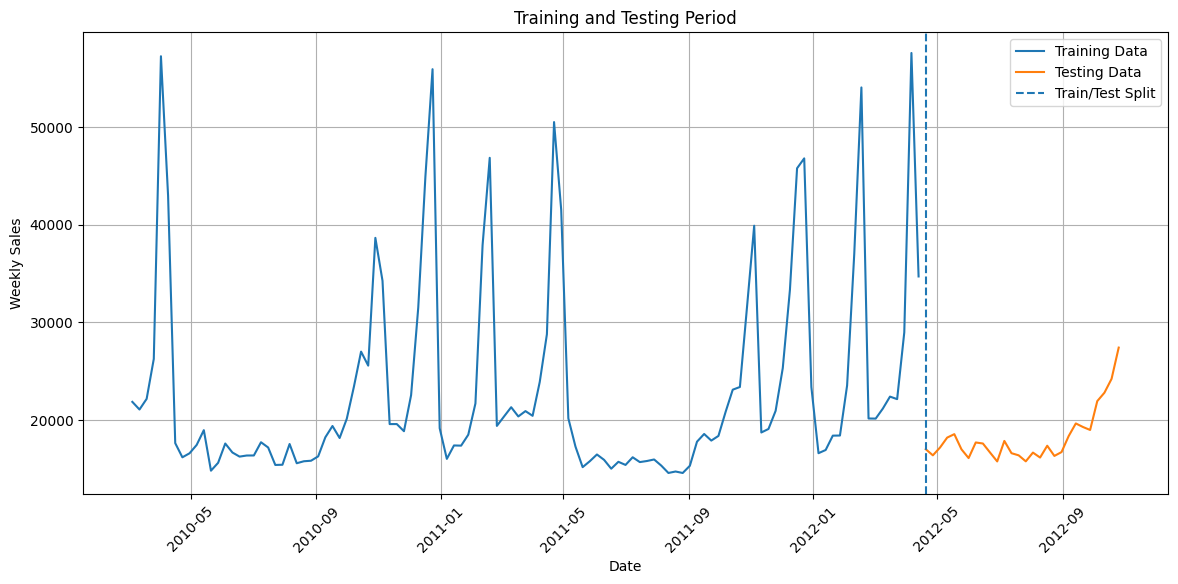

In [ ]:
plt.figure(figsize=(14, 6))

plt.plot(
    train_data['Date'],
    train_data['Weekly_Sales'],
    label='Training Data'
)

plt.plot(
    test_data['Date'],
    test_data['Weekly_Sales'],
    label='Testing Data'
)

plt.axvline(
    test_data['Date'].iloc[0],
    linestyle='--',
    label='Train/Test Split'
)

plt.title('Training and Testing Period')
plt.xlabel('Date')
plt.ylabel('Weekly Sales')
plt.xticks(rotation=45)
plt.legend()
plt.grid(True)

plt.show()

In [ ]:
X_train = train_data[['Lag_1', 'Lag_2', 'Lag_3', 'Lag_4']]
y_train = train_data['Weekly_Sales']

X_test = test_data[['Lag_1', 'Lag_2', 'Lag_3', 'Lag_4']]
y_test = test_data['Weekly_Sales']

print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)
print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)

X_train shape: (111, 4)
y_train shape: (111,)
X_test shape: (28, 4)
y_test shape: (28,)


In [ ]:
# 9. Baseline Linear Regression
from sklearn.linear_model import LinearRegression

model = LinearRegression()

model.fit(X_train, y_train)

print("Model training completed successfully!")

Model training completed successfully!


In [ ]:
print("Intercept:", model.intercept_)

print("\nCoefficients:")

for feature, coefficient in zip(X_train.columns, model.coef_):
    print(feature, ":", coefficient)

Intercept: 14018.750464190623

Coefficients:
Lag_1 : 0.7141643414021097
Lag_2 : -0.33823518706303196
Lag_3 : 0.11537277760516745
Lag_4 : -0.09460597137482346


In [ ]:
predictions = model.predict(X_test)

print("First 10 predictions:")
print(predictions[:10])

First 10 predictions:
[20558.14641879 18316.56916577 18504.73384203 19412.76392953
 21471.12589222 21531.49138288 20343.54880232 20172.488124
 21406.50207487 20832.03784981]


In [ ]:
comparison = pd.DataFrame({
    'Date': test_data['Date'].values,
    'Actual_Sales': y_test.values,
    'Predicted_Sales': predictions
})

comparison.head(10)

,Date,Actual_Sales,Predicted_Sales
0,2012-04-20,16976.19,20558.146419
1,2012-04-27,16347.60,18316.569166
2,2012-05-04,17147.44,18504.733842
3,2012-05-11,18164.20,19412.763930
4,2012-05-18,18517.79,21471.125892
5,2012-05-25,16963.55,21531.491383
6,2012-06-01,16065.49,20343.548802
7,2012-06-08,17666.00,20172.488124
8,2012-06-15,17558.82,21406.502075
9,2012-06-22,16633.41,20832.037850


In [ ]:
from sklearn.metrics import mean_absolute_percentage_error

mape = mean_absolute_percentage_error(y_test, predictions)

print("MAPE:", mape)
print("MAPE (%):", mape * 100)

MAPE: 0.17802733127880574
MAPE (%): 17.802733127880575


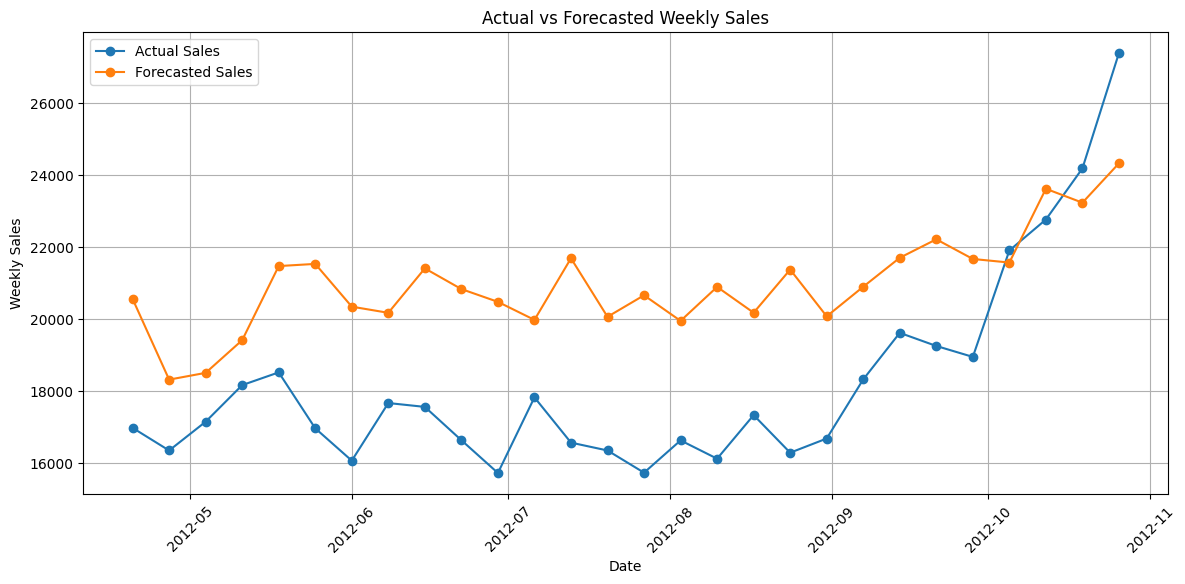

In [ ]:
plt.figure(figsize=(14, 6))

plt.plot(
    test_data['Date'],
    y_test.values,
    marker='o',
    label='Actual Sales'
)

plt.plot(
    test_data['Date'],
    predictions,
    marker='o',
    label='Forecasted Sales'
)

plt.title('Actual vs Forecasted Weekly Sales')
plt.xlabel('Date')
plt.ylabel('Weekly Sales')
plt.xticks(rotation=45)
plt.legend()
plt.grid(True)

plt.show()

In [ ]:
comparison['Error'] = (
    comparison['Actual_Sales'] -
    comparison['Predicted_Sales']
)

comparison['Absolute_Error'] = abs(comparison['Error'])

comparison.head(10)

,Date,Actual_Sales,Predicted_Sales,Error,Absolute_Error
0,2012-04-20,16976.19,20558.146419,-3581.956419,3581.956419
1,2012-04-27,16347.60,18316.569166,-1968.969166,1968.969166
2,2012-05-04,17147.44,18504.733842,-1357.293842,1357.293842
3,2012-05-11,18164.20,19412.763930,-1248.563930,1248.563930
4,2012-05-18,18517.79,21471.125892,-2953.335892,2953.335892
5,2012-05-25,16963.55,21531.491383,-4567.941383,4567.941383
6,2012-06-01,16065.49,20343.548802,-4278.058802,4278.058802
7,2012-06-08,17666.00,20172.488124,-2506.488124,2506.488124
8,2012-06-15,17558.82,21406.502075,-3847.682075,3847.682075
9,2012-06-22,16633.41,20832.037850,-4198.627850,4198.627850


In [ ]:
largest_errors = comparison.nlargest(
    5,
    'Absolute_Error'
)

largest_errors

,Date,Actual_Sales,Predicted_Sales,Error,Absolute_Error
12,2012-07-13,16566.18,21687.428288,-5121.248288,5121.248288
18,2012-08-24,16286.40,21373.585006,-5087.185006,5087.185006
14,2012-07-27,15731.18,20659.546020,-4928.366020,4928.366020
16,2012-08-10,16119.92,20892.119454,-4772.199454,4772.199454
10,2012-06-29,15722.82,20477.012197,-4754.192197,4754.192197


In [ ]:
# 10. Improved Model — Seasonal Feature Engineering
improved_data = store_dept[
    ['Date', 'Weekly_Sales', 'IsHoliday']
].copy()

improved_data = improved_data.sort_values('Date').reset_index(drop=True)

# Previous-week sales
improved_data['Lag_1'] = improved_data['Weekly_Sales'].shift(1)
improved_data['Lag_2'] = improved_data['Weekly_Sales'].shift(2)
improved_data['Lag_3'] = improved_data['Weekly_Sales'].shift(3)
improved_data['Lag_4'] = improved_data['Weekly_Sales'].shift(4)

# Same period approximately one year earlier
improved_data['Lag_52'] = improved_data['Weekly_Sales'].shift(52)

# Week of year
improved_data['Week_of_Year'] = (
    improved_data['Date']
    .dt.isocalendar()
    .week
    .astype(int)
)

improved_data.head()

,Date,Weekly_Sales,IsHoliday,Lag_1,Lag_2,Lag_3,Lag_4,Lag_52,Week_of_Year
0,2010-02-05,24924.50,False,NaN,NaN,NaN,NaN,NaN,5
1,2010-02-12,46039.49,True,24924.50,NaN,NaN,NaN,NaN,6
2,2010-02-19,41595.55,False,46039.49,24924.50,NaN,NaN,NaN,7
3,2010-02-26,19403.54,False,41595.55,46039.49,24924.50,NaN,NaN,8
4,2010-03-05,21827.90,False,19403.54,41595.55,46039.49,24924.5,NaN,9


In [ ]:
improved_data['Week_Sin'] = np.sin(
    2 * np.pi * improved_data['Week_of_Year'] / 52
)

improved_data['Week_Cos'] = np.cos(
    2 * np.pi * improved_data['Week_of_Year'] / 52
)

improved_data.head()

,Date,Weekly_Sales,IsHoliday,Lag_1,Lag_2,Lag_3,Lag_4,Lag_52,Week_of_Year,Week_Sin,Week_Cos
0,2010-02-05,24924.50,False,NaN,NaN,NaN,NaN,NaN,5,0.568065,0.822984
1,2010-02-12,46039.49,True,24924.50,NaN,NaN,NaN,NaN,6,0.663123,0.748511
2,2010-02-19,41595.55,False,46039.49,24924.50,NaN,NaN,NaN,7,0.748511,0.663123
3,2010-02-26,19403.54,False,41595.55,46039.49,24924.50,NaN,NaN,8,0.822984,0.568065
4,2010-03-05,21827.90,False,19403.54,41595.55,46039.49,24924.5,NaN,9,0.885456,0.464723


In [ ]:
improved_data = improved_data.dropna().reset_index(drop=True)

print("Rows available for improved model:", len(improved_data))

Rows available for improved model: 91


In [ ]:
features = [
    'Lag_1',
    'Lag_2',
    'Lag_3',
    'Lag_4',
    'Lag_52',
    'Week_Sin',
    'Week_Cos',
    'IsHoliday'
]

X = improved_data[features]
y = improved_data['Weekly_Sales']

print("Number of features:", len(features))
print("Features:", features)

Number of features: 8
Features: ['Lag_1', 'Lag_2', 'Lag_3', 'Lag_4', 'Lag_52', 'Week_Sin', 'Week_Cos', 'IsHoliday']


In [ ]:

train_size = int(len(improved_data) * 0.8)

X_train = X.iloc[:train_size]
X_test = X.iloc[train_size:]

y_train = y.iloc[:train_size]
y_test = y.iloc[train_size:]

test_dates = improved_data['Date'].iloc[train_size:]

print("Training observations:", len(X_train))
print("Testing observations:", len(X_test))

Training observations: 72
Testing observations: 19


In [ ]:
# 11. Improved Seasonal Regression
improved_model = LinearRegression()

improved_model.fit(X_train, y_train)

print("Improved model training completed!")

Improved model training completed!


In [ ]:
improved_predictions = improved_model.predict(X_test)

print("First 10 improved predictions:")
print(improved_predictions[:10])

First 10 improved predictions:
[17006.97990039 16326.43806747 15938.98959677 16928.10632816
 15471.63267081 15990.5220477  15204.15137931 15868.33812543
 15433.30860773 16466.30511217]


In [ ]:
improved_mape = mean_absolute_percentage_error(
    y_test,
    improved_predictions
)

print("Improved MAPE:", improved_mape)
print("Improved MAPE (%):", improved_mape * 100)

Improved MAPE: 0.0477828838235293
Improved MAPE (%): 4.77828838235293


In [ ]:
# 12. Model Comparison
comparison_metrics = pd.DataFrame({
    'Model': [
        'Baseline Linear Regression',
        'Improved Seasonal Regression'
    ],
    'MAPE (%)': [
        mape * 100,
        improved_mape * 100
    ]
})

comparison_metrics

,Model,MAPE (%)
0,Baseline Linear Regression,17.802733
1,Improved Seasonal Regression,4.778288


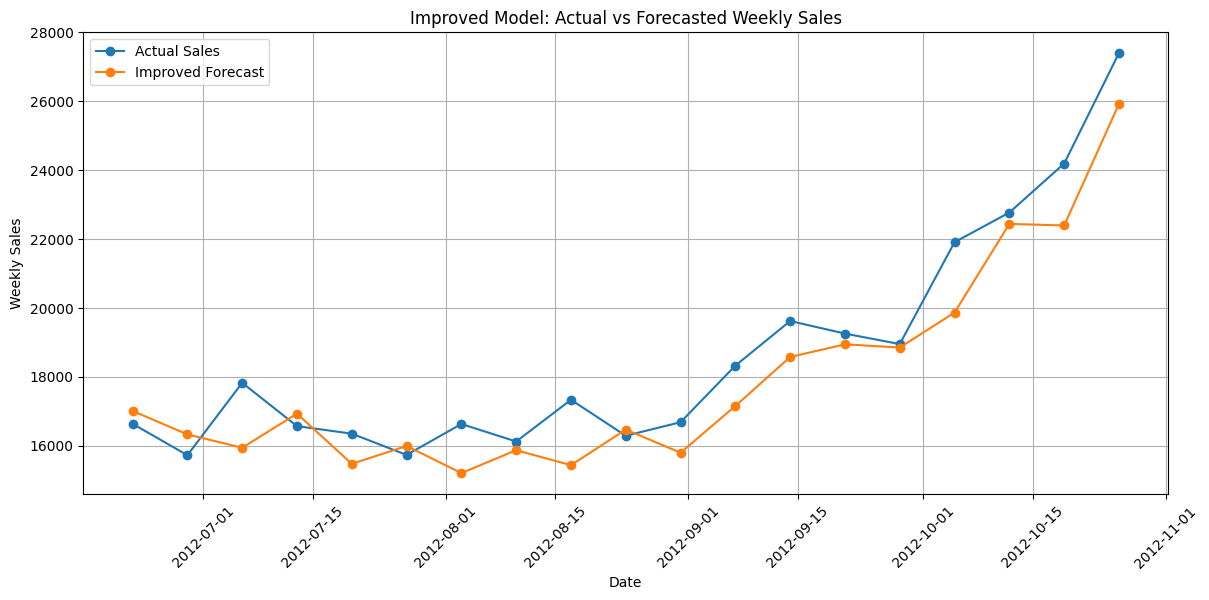

In [ ]:
plt.figure(figsize=(14, 6))

plt.plot(
    test_dates,
    y_test.values,
    marker='o',
    label='Actual Sales'
)

plt.plot(
    test_dates,
    improved_predictions,
    marker='o',
    label='Improved Forecast'
)

plt.title('Improved Model: Actual vs Forecasted Weekly Sales')
plt.xlabel('Date')
plt.ylabel('Weekly Sales')
plt.xticks(rotation=45)
plt.legend()
plt.grid(True)

plt.show()

In [ ]:
print(
    store_dept[
        ['Date', 'Weekly_Sales', 'IsHoliday']
    ].tail(5)
)

          Date  Weekly_Sales  IsHoliday
138 2012-09-28      18947.81      False
139 2012-10-05      21904.47      False
140 2012-10-12      22764.01      False
141 2012-10-19      24185.27      False
142 2012-10-26      27390.81      False


In [ ]:
final_model = LinearRegression()

final_model.fit(X, y)

print("Final model trained on all available historical data.")
print("Training observations:", len(X))

Final model trained on all available historical data.
Training observations: 91


In [ ]:
last_date = store_dept['Date'].max()

next_date = last_date + pd.Timedelta(days=7)

print("Last historical date:", last_date)
print("Forecast date:", next_date)

Last historical date: 2012-10-26 00:00:00
Forecast date: 2012-11-02 00:00:00


In [ ]:
features_df = pd.read_csv("features.csv")

features_df['Date'] = pd.to_datetime(features_df['Date'])

next_week_info = features_df[
    (features_df['Store'] == 1) &
    (features_df['Date'] == next_date)
]

next_week_info[['Date', 'IsHoliday']]

,Date,IsHoliday
143,2012-11-02,False


In [ ]:

last_sales = store_dept['Weekly_Sales'].values

lag_1 = last_sales[-1]
lag_2 = last_sales[-2]
lag_3 = last_sales[-3]
lag_4 = last_sales[-4]
lag_52 = last_sales[-52]

week_of_year = int(next_date.isocalendar().week)

week_sin = np.sin(2 * np.pi * week_of_year / 52)
week_cos = np.cos(2 * np.pi * week_of_year / 52)

is_holiday = int(next_week_info['IsHoliday'].iloc[0])

next_week_features = pd.DataFrame({
    'Lag_1': [lag_1],
    'Lag_2': [lag_2],
    'Lag_3': [lag_3],
    'Lag_4': [lag_4],
    'Lag_52': [lag_52],
    'Week_Sin': [week_sin],
    'Week_Cos': [week_cos],
    'IsHoliday': [is_holiday]
})

next_week_features

,Lag_1,Lag_2,Lag_3,Lag_4,Lag_52,Week_Sin,Week_Cos,IsHoliday
0,27390.81,24185.27,22764.01,21904.47,39886.06,-0.822984,0.568065,0


In [ ]:
# 13. Next-Week Demand Forecast
next_week_forecast = final_model.predict(
    next_week_features
)[0]

print(
    "Forecasted demand for",
    next_date.date(),
    ":",
    round(next_week_forecast, 2),
    "units"
)

Forecasted demand for 2012-11-02 : 29944.31 units


In [ ]:
# 14. Safety Stock Calculation
forecast_errors = y_test.values - improved_predictions

error_std = np.std(forecast_errors)

print(
    "Standard deviation of forecast errors:",
    round(error_std, 2)
)

Standard deviation of forecast errors: 854.94


In [ ]:
z_value = 1.645

safety_stock = z_value * error_std

print(
    "Safety stock:",
    round(safety_stock, 2),
    "units"
)

Safety stock: 1406.38 units


In [ ]:
# 15. Inventory Ordering Recommendation
recommended_order = next_week_forecast + safety_stock

print("========== ORDERING RECOMMENDATION ==========")
print("Forecasted demand:", round(next_week_forecast, 2), "units")
print("Safety stock:", round(safety_stock, 2), "units")
print("Recommended order quantity:", round(recommended_order), "units")

========== ORDERING RECOMMENDATION ==========
Forecasted demand: 29944.31 units
Safety stock: 1406.38 units
Recommended order quantity: 31351 units


In [ ]:
store_features = features_df[
    features_df['Store'] == 1
].copy()

print(store_features.shape)

store_features.head()

(182, 12)


,Store,Date,Temperature,Fuel_Price,MarkDown1,MarkDown2,MarkDown3,MarkDown4,MarkDown5,CPI,Unemployment,IsHoliday
0,1,2010-02-05,42.31,2.572,NaN,NaN,NaN,NaN,NaN,211.096358,8.106,False
1,1,2010-02-12,38.51,2.548,NaN,NaN,NaN,NaN,NaN,211.242170,8.106,True
2,1,2010-02-19,39.93,2.514,NaN,NaN,NaN,NaN,NaN,211.289143,8.106,False
3,1,2010-02-26,46.63,2.561,NaN,NaN,NaN,NaN,NaN,211.319643,8.106,False
4,1,2010-03-05,46.50,2.625,NaN,NaN,NaN,NaN,NaN,211.350143,8.106,False


In [ ]:
markdown_columns = [
    'MarkDown1',
    'MarkDown2',
    'MarkDown3',
    'MarkDown4',
    'MarkDown5'
]

print(
    store_features[markdown_columns].notna().sum()
)

MarkDown1    90
MarkDown2    73
MarkDown3    89
MarkDown4    90
MarkDown5    90
dtype: int64


In [ ]:

store_features['Total_MarkDown'] = (
    store_features[markdown_columns]
    .fillna(0)
    .sum(axis=1)
)

store_features[
    ['Date', 'Total_MarkDown']
].head(10)

,Date,Total_MarkDown
0,2010-02-05,0.0
1,2010-02-12,0.0
2,2010-02-19,0.0
3,2010-02-26,0.0
4,2010-03-05,0.0
5,2010-03-12,0.0
6,2010-03-19,0.0
7,2010-03-26,0.0
8,2010-04-02,0.0
9,2010-04-09,0.0


In [ ]:
top_promotions = store_features.nlargest(
    10,
    'Total_MarkDown'
)[
    ['Date', 'Total_MarkDown', 'IsHoliday']
]

print(top_promotions)

          Date  Total_MarkDown  IsHoliday
158 2013-02-15        98974.87      False
104 2012-02-03        76351.07      False
146 2012-11-23        76311.31       True
157 2013-02-08        58464.24       True
99  2011-12-30        57753.27       True
94  2011-11-25        56876.74       True
151 2012-12-28        51218.78       True
108 2012-03-02        50479.69      False
159 2013-02-22        44784.00      False
130 2012-08-03        44403.74      False


In [ ]:
sales_promo = store_dept[
    ['Date', 'Weekly_Sales', 'IsHoliday']
].merge(
    store_features[
        ['Date', 'Total_MarkDown']
    ],
    on='Date',
    how='left'
)

sales_promo['Total_MarkDown'] = (
    sales_promo['Total_MarkDown']
    .fillna(0)
)

sales_promo.head()

,Date,Weekly_Sales,IsHoliday,Total_MarkDown
0,2010-02-05,24924.50,False,0.0
1,2010-02-12,46039.49,True,0.0
2,2010-02-19,41595.55,False,0.0
3,2010-02-26,19403.54,False,0.0
4,2010-03-05,21827.90,False,0.0


In [ ]:
# 16. Promotion & Markdown Analysis
sales_promo['Promotion'] = (
    sales_promo['Total_MarkDown'] > 0
)

promotion_comparison = (
    sales_promo
    .groupby('Promotion')['Weekly_Sales']
    .mean()
)

print(promotion_comparison)

Promotion
False    22442.782717
True     22640.571961
Name: Weekly_Sales, dtype: float64


# Retraining Strategy

The forecasting model will initially be retrained on a weekly basis.

At the end of each week:

1. Collect the latest sales data.
2. Add the new weekly observation to the historical dataset.
3. Recalculate the lag and seasonal features.
4. Retrain the forecasting model using the updated historical data.
5. Generate the forecast for the following week.
6. Calculate the recommended order quantity using the forecast and safety stock.

The retraining frequency can be adjusted if forecast accuracy decreases or if significant changes in demand patterns are observed.

# Handling Promotions and Festivals

Promotions and festivals can create demand shocks that differ from normal sales patterns.

The current analysis shows that holiday weeks have higher average sales than non-holiday weeks. However, not all major sales spikes occur during holidays.

Markdown analysis for the selected Store 1 and Department 1 shows similar average sales between markdown and non-markdown weeks. Therefore, markdown activity alone does not explain all demand variation.

For a more advanced version of the model, promotion and festival indicators can be included as external features. Festival periods can also be evaluated separately to determine whether the model performs differently during demand shocks.

# Conclusion

The project developed a machine-learning-based weekly retail demand forecasting system using Walmart sales data.

A baseline Linear Regression model using recent sales lags achieved a MAPE of 17.80%. After incorporating yearly lag information, cyclical seasonal features, and holiday information, the MAPE improved to 4.78%.

The final model was used to forecast approximately 29,944 units of demand for the following week. Based on forecast uncertainty, approximately 1,406 units were added as safety stock, resulting in a recommended order quantity of approximately 31,351 units.

The system can be retrained weekly as new sales data becomes available.